# 01: k-nearest neighbors

**The algorithm.** To classify a point, find the k training rows closest to it and take a vote.

**Where the time goes.** For every query, the distance to every training row: that part is a matrix multiply, which hardware is great at. Then *picking the k smallest* out of hundreds of thousands of distances per query. That part is memory-bound sorting work, and it's where naive implementations lose.

**Data.** Covertype: 581,012 forest plots, 54 features, 7 tree-cover classes. Standardized, float32. 2,000 rows are held out as queries.

In [1]:
import sys
sys.path.insert(0, ".")  # so bench_utils (next to this notebook) imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ml_in_rust as mr
from bench_utils import (machine_info, timeit, load_covtype, add_speedup,
                         save_results, line_chart, fmt_ms, only_available)

pd.set_option("display.float_format", "{:,.4f}".format)
%matplotlib inline
pd.Series(machine_info())

machine                                    macos-arm64-apple-m4
cpu                                                    Apple M4
cores                              4 performance + 6 efficiency
ram_gb                                                       24
os                          macOS-26.6.1-arm64-arm-64bit-Mach-O
python                                                   3.13.5
numpy                                  2.5.4 (BLAS: accelerate)
sklearn                                                   1.9.1
rust-blas matrix library                       Apple Accelerate
mlx                                     0.32.4 (Device(gpu, 0))
dtype: object

In [2]:
import os
QUICK = os.environ.get("QUICK") == "1"  # QUICK=1 ./run_all.sh for a fast smoke run

X, y = load_covtype()
Xq, yq = X[:2000], y[:2000]
X_pool, y_pool = X[2000:], y[2000:]
SIZES = [10_000, 50_000] if QUICK else [10_000, 50_000, 200_000, len(X_pool)]
K = 5

from sklearn.neighbors import KNeighborsClassifier as SkKNN

def engines(k=K):
    return only_available({
        "sklearn": SkKNN(n_neighbors=k, n_jobs=-1),
        "numpy": mr.KNeighborsClassifier(k, backend="numpy"),
        "rust": mr.KNeighborsClassifier(k, backend="rust"),
        "rust-blas": mr.KNeighborsClassifier(k, backend="rust-blas"),
        "mlx": mr.KNeighborsClassifier(k, backend="mlx"),
    })
print(f"{len(X_pool):,} training rows available, {len(Xq):,} queries")

579,012 training rows available, 2,000 queries


## Race 1: batch prediction as the training set grows

Each engine predicts all 2,000 queries. Times are the median of 3 runs after a warm-up call. "vs sklearn" above 1 means faster than scikit-learn.

In [3]:
rows = []
for n in SIZES:
    ref_pred = None
    for name, model in engines().items():
        model.fit(X_pool[:n], y_pool[:n])
        t = timeit(lambda: model.predict(Xq))
        pred = model.predict(Xq)
        if name == "sklearn":
            ref_pred = pred
        rows.append({"train rows": n, "engine": name, "predict s": t,
                     "accuracy": np.mean(pred == yq), "agrees with sklearn": np.mean(pred == ref_pred)})
batch = add_speedup(pd.DataFrame(rows), "predict s", ["train rows"])
batch.pivot(index="train rows", columns="engine", values="vs sklearn").round(2)

engine,mlx,numpy,rust,rust-blas,sklearn
train rows,,,,,
10000,1.7500,0.1400,1.0900,4.4400,1.0000
50000,1.1800,0.0800,0.7500,3.4500,1.0000
200000,0.9300,0.1300,0.6100,3.1100,1.0000
579012,0.8400,0.1200,0.5800,2.8700,1.0000


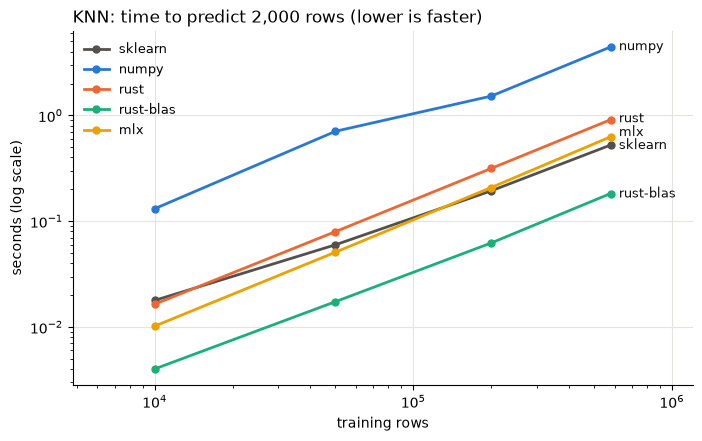

,train rows,engine,predict s,accuracy,agrees with sklearn,vs sklearn
0,10000,sklearn,0.0178,0.7615,1.0000,1.0000
1,10000,numpy,0.1313,0.7615,1.0000,0.1359
2,10000,rust,0.0164,0.7615,1.0000,1.0855
3,10000,rust-blas,0.0040,0.7615,1.0000,4.4438
4,10000,mlx,0.0102,0.7615,1.0000,1.7496
5,50000,sklearn,0.0599,0.8445,1.0000,1.0000
6,50000,numpy,0.7076,0.8445,1.0000,0.0846
7,50000,rust,0.0797,0.8445,1.0000,0.7508
8,50000,rust-blas,0.0174,0.8445,1.0000,3.4473
9,50000,mlx,0.0509,0.8445,1.0000,1.1753


In [4]:
line_chart(batch, "train rows", "predict s", "KNN: time to predict 2,000 rows (lower is faster)",
           "training rows", "seconds (log scale)")
plt.show()
batch

## Race 2: one prediction at a time

A robot, a game or a live API predicts one row at a time. Here the fixed cost of each call matters more than raw math speed.

In [5]:
lat_rows = []
for n in ([10_000] if QUICK else [10_000, 200_000]):
    for name, model in engines().items():
        model.fit(X_pool[:n], y_pool[:n])
        model.predict(Xq[:1])
        times = []
        for i in range(300):
            q = Xq[i:i + 1]
            t0 = __import__("time").perf_counter()
            model.predict(q)
            times.append(__import__("time").perf_counter() - t0)
        lat_rows.append({"train rows": n, "engine": name, "median µs": np.median(times) * 1e6,
                         "p95 µs": np.percentile(times, 95) * 1e6})
latency = add_speedup(pd.DataFrame(lat_rows), "median µs", ["train rows"])
latency

,train rows,engine,median µs,p95 µs,vs sklearn
0,10000,sklearn,422.8960,718.7205,1.0000
1,10000,numpy,92.8125,124.9663,4.5565
2,10000,rust,48.6251,49.5461,8.6971
3,10000,rust-blas,36.9795,37.4191,11.4360
4,10000,mlx,391.7915,465.6708,1.0794
5,200000,sklearn,"2,322.9795","2,749.1459",1.0000
6,200000,numpy,"1,189.7290","1,805.0857",1.9525
7,200000,rust,749.0830,761.9747,3.1011
8,200000,rust-blas,836.7500,845.7709,2.7762
9,200000,mlx,965.6250,"1,543.8789",2.4057


## Race 3: does k change the picture?

The Rust engines keep the k best candidates in a small sorted list, which gets more expensive as k grows. NumPy and MLX use a partial sort whose cost barely depends on k. This race checks whether that matters in practice.

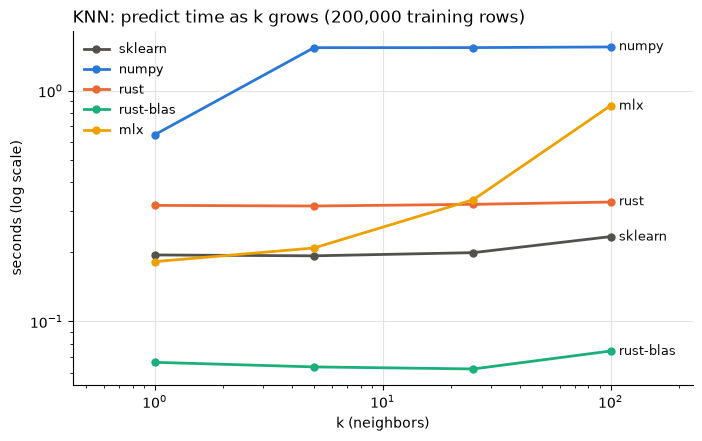

engine,mlx,numpy,rust,rust-blas,sklearn
k,,,,,
1,1.0700,0.3000,0.6100,2.9200,1.0000
5,0.9200,0.1300,0.6100,3.0300,1.0000
25,0.5900,0.1300,0.6200,3.1900,1.0000
100,0.2700,0.1500,0.7100,3.1300,1.0000


In [6]:
n = 50_000 if QUICK else 200_000
k_rows = []
for k in [1, 5, 25, 100]:
    for name, model in engines(k).items():
        model.fit(X_pool[:n], y_pool[:n])
        k_rows.append({"k": k, "engine": name, "predict s": timeit(lambda: model.predict(Xq), repeats=2)})
by_k = add_speedup(pd.DataFrame(k_rows), "predict s", ["k"])
line_chart(by_k, "k", "predict s", f"KNN: predict time as k grows ({n:,} training rows)",
           "k (neighbors)", "seconds (log scale)")
plt.show()
by_k.pivot(index="k", columns="engine", values="vs sklearn").round(2)

In [7]:
save_results("knn", batch, notes={
    "latency": latency.to_dict(orient="records"),
    "by_k": by_k.to_dict(orient="records"),
})
largest = batch[batch["train rows"] == batch["train rows"].max()].set_index("engine")
print("At the largest size, speed vs scikit-learn:")
print(largest["vs sklearn"].round(2).to_string())

At the largest size, speed vs scikit-learn:
engine
sklearn     1.0000
numpy       0.1200
rust        0.5800
rust-blas   2.8700
mlx         0.8400
